# Image Reconstruction

**Part:** F — Image formation · **Reading time:** ~60 min · **Pass 1 overview:** [From Signal to Image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs and sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb), [Complex numbers](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)

**Image reconstruction** is the step that turns the raw numbers the scanner records (the k-space data) into the picture a radiologist looks at. For the standard Cartesian acquisition it is "just" an inverse discrete Fourier transform — but doing it *correctly* requires care with array ordering (centered FFTs), with complex values (magnitude vs. phase), with multiple receive coils, and with oversampled readouts. Writing the reconstruction as a **linear system** $\mathbf{y}=\mathbf{F}\mathbf{x}+\mathbf{n}$ also prepares you for every advanced method (parallel imaging, compressed sensing, deep learning), which all start from that equation.

## Learning goals

1. Describe how images are formed
    * Describe how MRI raw data is reconstructed into an image
    * Explain why the discrete inverse Fourier transform of sampled k-space approximates the object
    * Explain the centered-FFT convention and what goes wrong without it
1. Manipulate and analyze MRI data
    * Reconstruct an image from raw data (single-coil brain, oversampled knee, 3D spectroscopic phantom)
    * Show and interpret magnitude **and** phase images
    * Combine images from several receive coils with the root-sum-of-squares method
    * Formulate reconstruction as a linear system and verify it against the FFT
1. Know where reconstruction gets harder: conjugate (Hermitian) symmetry and why real data violate it, non-Cartesian sampling and gridding

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r=[x,y,z]^T$ | position in the body | m | $x$ = readout, $y$ = phase-encode direction here |
| $\vec k=[k_x,k_y,k_z]^T$ | k-space position (spatial frequency) | m⁻¹ (cycles/m) | $\vec k(t)=\bar\gamma\int_0^t\vec G\,d\tau$, see [K-space](F2_K-space.ipynb) |
| $\vec k_i(t)$ | k-space trajectory during the $i$-th TR (repetition) | m⁻¹ | one line of k-space per TR in Cartesian imaging |
| $\bar\gamma$ | gyromagnetic ratio $\gamma/2\pi$ | Hz/T | 42.58 MHz/T for ¹H |
| $\vec G(t)$ | gradient waveform | T/m | 10–80 mT/m |
| $M_{xy}(\vec r,t)$ | transverse magnetization ($M_x+iM_y$) | a.u. ($M_0=1$) | complex number |
| $m(\vec r)$ | the "image": $M_{xy}$ right after excitation / at TE | a.u. | complex-valued |
| $M(\vec k)=\mathcal F\{m\}$ | k-space data = Fourier transform of the image (**not** the magnetization vector $\vec M$) | a.u. | complex |
| $s(t)$, $s_i(t)$ | received (demodulated) signal; in the $i$-th TR | V (a.u.) | |
| $\mathcal F$, $\mathcal F^{-1}$ | (inverse) Fourier transform | | kernel $e^{-i2\pi kx}$ |
| $N$, $N_{read}$, $N_{PE}$ | matrix size; readout samples; phase-encode lines | – | 128–512 |
| $\Delta k$ | spacing of k-space samples | m⁻¹ | $=1/FOV$ |
| $FOV$ | field of view | m | 0.2–0.5 m |
| $\delta$ | pixel size $=FOV/N$ | m | 0.5–2 mm |
| $\Delta t$ | dwell time between ADC samples | s | 2–20 µs |
| $\mathbf{x}$ | image written as a column **vector** of pixel values (bold — not the position $x$!) | a.u. | length $N_{pix}$ |
| $\mathbf{y}$ | measured k-space samples as a column vector | a.u. | length $N_{samp}$ |
| $\mathbf{n}$ | measurement noise vector | a.u. | complex Gaussian |
| $\mathbf{F}$ | encoding (DFT) matrix, entries $\mathbf F_{pq}=e^{-i2\pi\vec k_p\cdot\vec r_q}$ | – | $N_{samp}\times N_{pix}$ |
| $p$, $q$ | row index (k-space sample) and column index (pixel) | – | renamed from the original's $i,j$ to avoid clashing with $i=\sqrt{-1}$ |
| $(\cdot)^H$ | conjugate transpose ("Hermitian") | | |
| $(\cdot)^*$ | complex conjugate | | not convolution here |
| $i$ | imaginary unit $\sqrt{-1}$ | | |
| $N_c$ | number of receive-coil elements (channels) | – | 8–64 |
| $C_n(\vec r)$ | complex receive sensitivity of coil $n$ | – | smooth, largest near the coil |
| $m_n(\vec r)$ | image seen by coil $n$: $C_n(\vec r)\,m(\vec r)$ | a.u. | |
| $m_{SoS}$ | root-sum-of-squares combined image | a.u. | |
| $\sigma_n$ | standard deviation of the noise (per real/imaginary part) | a.u. | |
| $w_p$ | density-compensation weight of sample $p$ (non-Cartesian) | – | $\propto\lvert\vec k_p\rvert$ for radial |
| $OS$ | readout oversampling factor | – | 2 (common default) |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Sorting the MRI data into k-space

Recall from [K-space](F2_K-space.ipynb) that the MRI signal is (proportional to) the Fourier transform of the transverse magnetization of the object, evaluated at the k-space location defined by the gradients:

$$ s_i(t) = \mathcal{F} \{ M_{xy}(\vec{r},0) \} \big|_{\vec{k} = \vec{k}_i(t)} = M\big(\vec k_i(t)\big)$$

In words: the number the receiver records at time $t$ during the $i$-th repetition is the value of the object's spectrum $M(\vec k)$ at the point $\vec k_i(t)$ where the gradients have "parked" us at that moment.

where
* $s_i(t)$ = demodulated signal in the $i$-th repetition (TR), as a function of time $t$ within the readout,
* $\vec k_i(t)=\bar\gamma\int_0^t\vec G_i(\tau)\,d\tau$ = k-space trajectory of that repetition (time measured from the excitation),
* $M(\vec k)=\mathcal F\{m(\vec r)\}=\int m(\vec r)e^{-i2\pi\vec k\cdot\vec r}d\vec r$ = k-space data, $m(\vec r)=M_{xy}(\vec r,0)$.

Note that this includes a dimension for the readout, $t$, as well as different readouts for each TR, denoted by the subscript $i$. Relaxation and off-resonance during the readout are ignored here (see [MRI Signal Equation](C2_MRI_Signal_Equation.ipynb) and [Artifacts](I2_Artifacts.ipynb)).

The data acquired during the readout are sorted into a matrix based on the k-space trajectory. The animation shows the Cartesian k-space trajectory, which acquires data in a raster fashion:

![Cartesian k-space trajectory and pulse sequence: gradients (left), M_xy phase (middle), k-space position (right)](../images/frequency_phase_encoding-full-image_phase.gif)

For a **Cartesian** acquisition the sorting is trivial:

| Raw-data index | k-space coordinate |
|---|---|
| ADC sample $q_x=0,\dots,N_{read}-1$ in each readout (time $t=TE+(q_x-N_{read}/2)\Delta t$) | $k_x=(q_x-N_{read}/2)\,\Delta k_x$ |
| phase-encode step (TR) $q_y=0,\dots,N_{PE}-1$ | $k_y=(q_y-N_{PE}/2)\,\Delta k_y$ |

so the scanner simply stacks each readout as one row of an $N_{PE}\times N_{read}$ complex matrix — the readout direction varies along a row, the phase-encode direction from row to row. From this knowledge, the MR signal over time is stored in a data matrix with known k-space locations to create $M(\vec{k})$.

> **🔧 Engineering reality:** The "raw data" leaving the receiver is already *digitized and demodulated* (shifted from ~128 MHz at 3 T down to ±BW/2 around 0 Hz, see [RF System and Receive Chain](B5_RF_System_and_Receive_Chain.ipynb)), stored as complex 16- or 32-bit numbers. One 2D slice of $256\times256$ complex64 samples is 0.5 MB *per coil*; with 32 coils, 2× readout oversampling and 30 slices that is ≈ 1 GB per series. Reconstruction runs on a dedicated computer (multi-core CPUs plus GPUs) next to the scanner, usually so fast that images appear while the next scan is already running.

## 2. Why an inverse DFT gives the image

The continuous relation is $m(\vec r)=\mathcal F^{-1}\{M(\vec k)\}$. We never have $M(\vec k)$ everywhere, only on a grid of $N$ points spaced $\Delta k$ apart. Replacing the integral by a sum (1D for clarity):

$$ \hat m(x) = \sum_{p=-N/2}^{N/2-1} M(p\,\Delta k)\, e^{+i2\pi p\Delta k\, x}\,\Delta k $$

In words: the reconstructed image at position $x$ is a weighted sum of all the measured k-space samples, each multiplied by its "stripe pattern" (complex exponential) $e^{+i2\pi kx}$ — exactly the inverse Fourier integral, evaluated as a Riemann sum.

where $\hat m$ = reconstructed (estimated) image, $p$ = k-space sample index, $\Delta k$ = k-space sample spacing [m⁻¹], $N$ = number of samples.

If we evaluate $\hat m$ only at the $N$ pixel positions $x_q=q\,\delta$ with $\delta=1/(N\Delta k)=FOV/N$, the exponent becomes $i2\pi pq/N$, and the sum **is exactly an inverse DFT** — which the FFT computes in $O(N\log N)$ operations. Two consequences of sampling (proved in [FOV and Resolution](G1_FOV_and_Resolution.ipynb), refresher [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)):

* the reconstructed image is periodic with period $1/\Delta k = FOV$ (anything outside wraps around — **aliasing**),
* it is the true object blurred by a sinc of width $\approx 1/(N\Delta k)=\delta$ (finite resolution).

> **🔁 Refresher:** continuous FT vs. DFT, and how the DFT is a sampled version of the FT: [RM3 Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb). The 2D version (each k-space point = one 2D stripe pattern) is in [RM6 2D Fourier and Images](../refreshers/RM6_2D_Fourier_and_Images.ipynb).

## 3. Fourier transform reconstruction

Once the data has been sorted into the corresponding lines in k-space, an inverse Fourier transform is applied to reconstruct an image of the transverse magnetization:

$$\mathcal{F}^{-1}\{ M(\vec{k} )\} = m(\vec{r})$$

In words: undo the Fourier transform the scanner "performed" physically, and you get back the transverse magnetization map.

For typical Cartesian sampling this is done very simply with the 2D or 3D **Fast Fourier Transform (FFT)** algorithm. Because the 2D FT is **separable** (a 1D FT along every row, then along every column — [RM6](../refreshers/RM6_2D_Fourier_and_Images.ipynb)), a 2D reconstruction is just two passes of 1D FFTs.

The animation shows k-space data as it is acquired line by line (left) and the image reconstructed from the lines accumulated so far (right):

![Image formation from sequential Cartesian k-space data](../images/image_formation_sequential.gif)

We can also acquire our k-space lines in a "center-out" or random ordering:

![Image formation from center-out Cartesian k-space data](../images/image_formation_centerout_lines.gif)
![Image formation from random Cartesian k-space data](../images/image_formation_random_lines.gif)

### 3.1 Reconstructing the provided sagittal brain data

The file `../data/se_t1_sag_data.mat` holds one fully sampled $256\times256$ single-coil k-space of a T1-weighted spin-echo sagittal brain scan (variable `data`). The following cell is the original chapter's code, ported to use `mt.ifft2c` (centered inverse 2D FFT, explained in Section 4). We display $\log_{10}|M|$ for k-space because its values span many orders of magnitude.

k-space shape: (256, 256) complex128
largest |sample| at index (127, 127) (the k = 0 index of a centered 256-array is N/2 = 128)


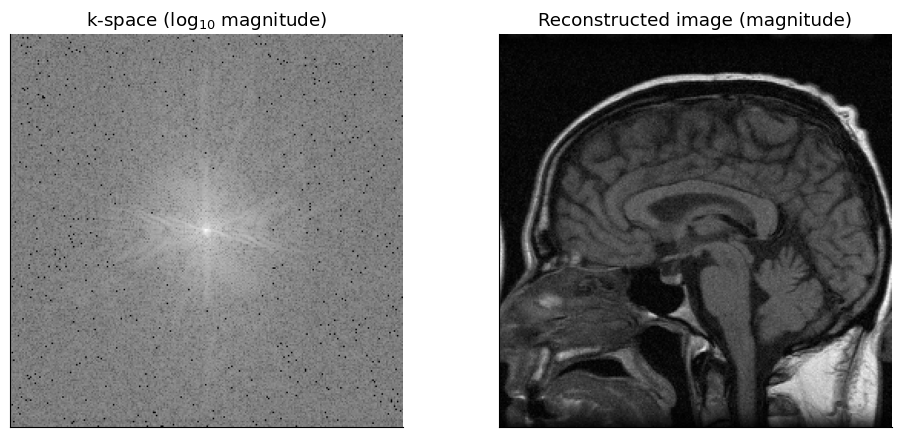

In [2]:
from scipy.io import loadmat

# Load k-space data from .mat file (rows = phase-encode lines k_y, columns = readout k_x)
kspace = loadmat('../data/se_t1_sag_data.mat')['data']
print("k-space shape:", kspace.shape, kspace.dtype)
print("largest |sample| at index", np.unravel_index(np.argmax(np.abs(kspace)), kspace.shape),
      "(the k = 0 index of a centered 256-array is N/2 = 128)")

# Reconstruct the image by a centered inverse 2D FFT
recon_image = mt.ifft2c(kspace)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
mt.show_kspace(kspace, ax=axs[0], title='k-space (log$_{10}$ magnitude)')
mt.show_image(recon_image, ax=axs[1], title='Reconstructed image (magnitude)')
plt.tight_layout(); plt.show()

The k-space is brightest at the center (low spatial frequencies = overall shape and contrast) and weak at the edges (fine detail and edges); the magnitude image is the familiar sagittal brain.

### 3.2 Magnitude *and* phase

$m(\vec r)$ is **complex**. Scanners normally show only the **magnitude** $|m|$, but the **phase** $\angle m$ carries information too (and sometimes problems). Phase in a real image comes from: the receive coil's own complex sensitivity $C(\vec r)$, static field inhomogeneity $\Delta B_0(\vec r)$ acting during TE, small timing offsets of the echo relative to the gradients (a shift in k-space = a linear phase ramp in the image — [shift theorem, RM4](../refreshers/RM4_Fourier_Properties.ipynb)), and flow/motion.

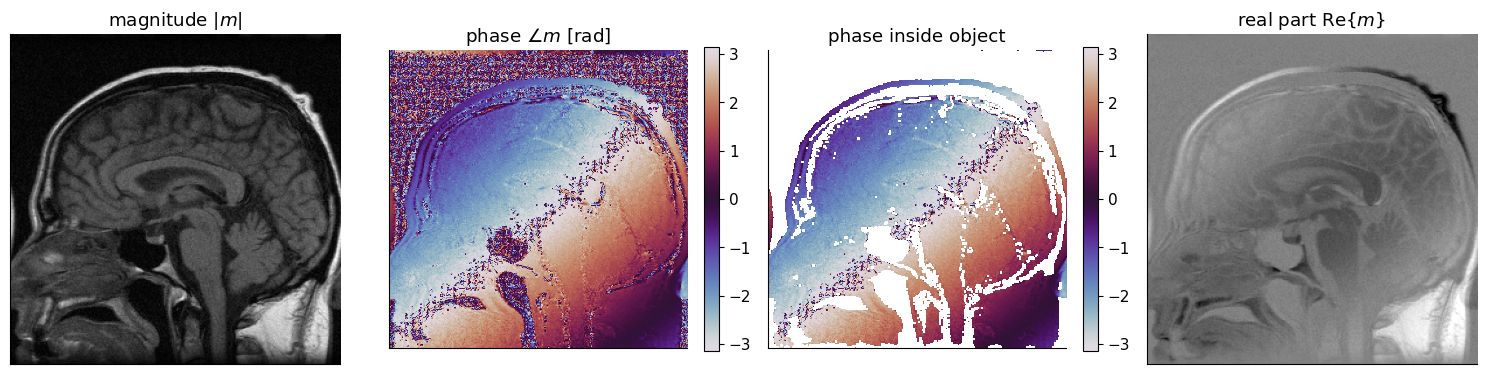

In [3]:
mag = np.abs(recon_image)
phs = np.angle(recon_image)                  # radians, in (-pi, pi]
mask = mag > 0.08 * mag.max()                # crude "object" mask: phase of pure noise is random

fig, axs = plt.subplots(1, 4, figsize=(15, 4))
mt.show_image(mag, ax=axs[0], title='magnitude $|m|$')
im = axs[1].imshow(phs, cmap='twilight', vmin=-np.pi, vmax=np.pi); axs[1].set_title(r'phase $\angle m$ [rad]')
plt.colorbar(im, ax=axs[1], fraction=0.046)
im = axs[2].imshow(np.where(mask, phs, np.nan), cmap='twilight', vmin=-np.pi, vmax=np.pi)
axs[2].set_title('phase inside object'); plt.colorbar(im, ax=axs[2], fraction=0.046)
v = np.percentile(mag, 99.5)
mt.show_image(recon_image.real, ax=axs[3], cmap='gray', vmin=-v, vmax=v, title='real part Re$\\{m\\}$')
for a in axs[1:3]:
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
plt.tight_layout(); plt.show()

The phase varies smoothly across the head and wraps at $\pm\pi$; in the background it is random because there only noise exists. The real part shows dark bands where the phase passes $\pm\pi/2$ — this is why magnitude images are the default display.

Notice the printout above: the echo peak sits at index (127, 127), **one sample before** the nominal center (128, 128). By the shift theorem, a k-space shift of one sample $\Delta k$ multiplies the image by $e^{-i2\pi\Delta k\,x}$ — one full $2\pi$ phase cycle across the FOV in each direction. That contributes a diagonal phase ramp to the phase map. Let us shift the data by one sample and look again:

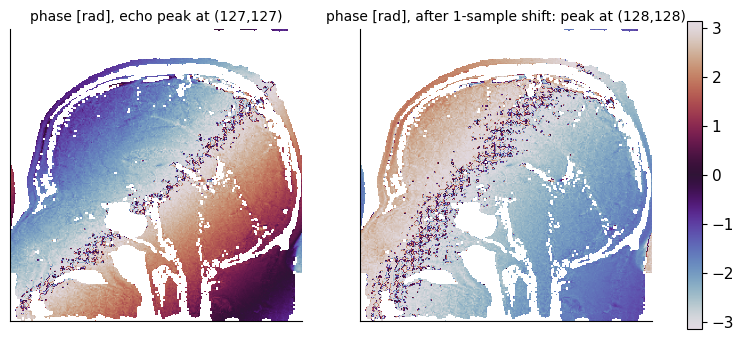

magnitude unchanged by the shift: True


In [4]:
k_recentered = np.roll(kspace, shift=(1, 1), axis=(0, 1))    # move the echo peak to index (128, 128)
img_rc = mt.ifft2c(k_recentered)
fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for ax, im_, t in [(axs[0], recon_image, 'echo peak at (127,127)'), (axs[1], img_rc, 'after 1-sample shift: peak at (128,128)')]:
    h = ax.imshow(np.where(mask, np.angle(im_), np.nan), cmap='twilight', vmin=-np.pi, vmax=np.pi)
    ax.set_title('phase [rad], ' + t, fontsize=10); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.colorbar(h, ax=axs, fraction=0.03)
plt.show()
print("magnitude unchanged by the shift:", np.allclose(np.abs(img_rc), np.abs(recon_image)))

The phase pattern changes by exactly one $2\pi$ cycle across the FOV in each direction (fewer wraps, different orientation). What remains is the smoothly varying phase from the coil and the $B_0$ field, plus whatever *fraction* of a sample the echo is still off-center — a pure integer shift cannot remove that. The hatched bands (skull, sinuses) are low-signal pixels just above the mask threshold, where the phase is dominated by noise. The magnitude is untouched (a circular shift of k-space only changes the image phase). Echo-centering errors of a fraction of a sample (gradient delays, eddy currents) are common and are why scanners apply phase corrections before, e.g., partial-Fourier reconstruction.

> **⚠️ Common confusion:** "The image is real because tissue is real." The *object property* (proton density, relaxation) is real, but $m(\vec r)$ is a complex magnetization multiplied by a complex coil sensitivity and phase-shifted by field errors. Taking $|m|$ throws away the phase (and with it, valuable information used for phase-contrast flow, susceptibility mapping, fat–water separation, and $B_0$ mapping), and changes the noise statistics (Rician noise, see [Signal to Noise Ratio](G2_Signal_to_Noise_Ratio.ipynb)).

### 3.3 Watching the image build up line by line (port of `animate_image_formation.m`)

The original GIFs were made by inserting k-space lines one at a time into an empty matrix and reconstructing after each insertion. Here are snapshots for three orderings. Notice that **center-out** ordering gives a recognizable (blurry) image after very few lines, because the central lines carry most of the energy — while **sequential** ordering shows almost nothing until the center line ($k_y=0$) arrives halfway through.

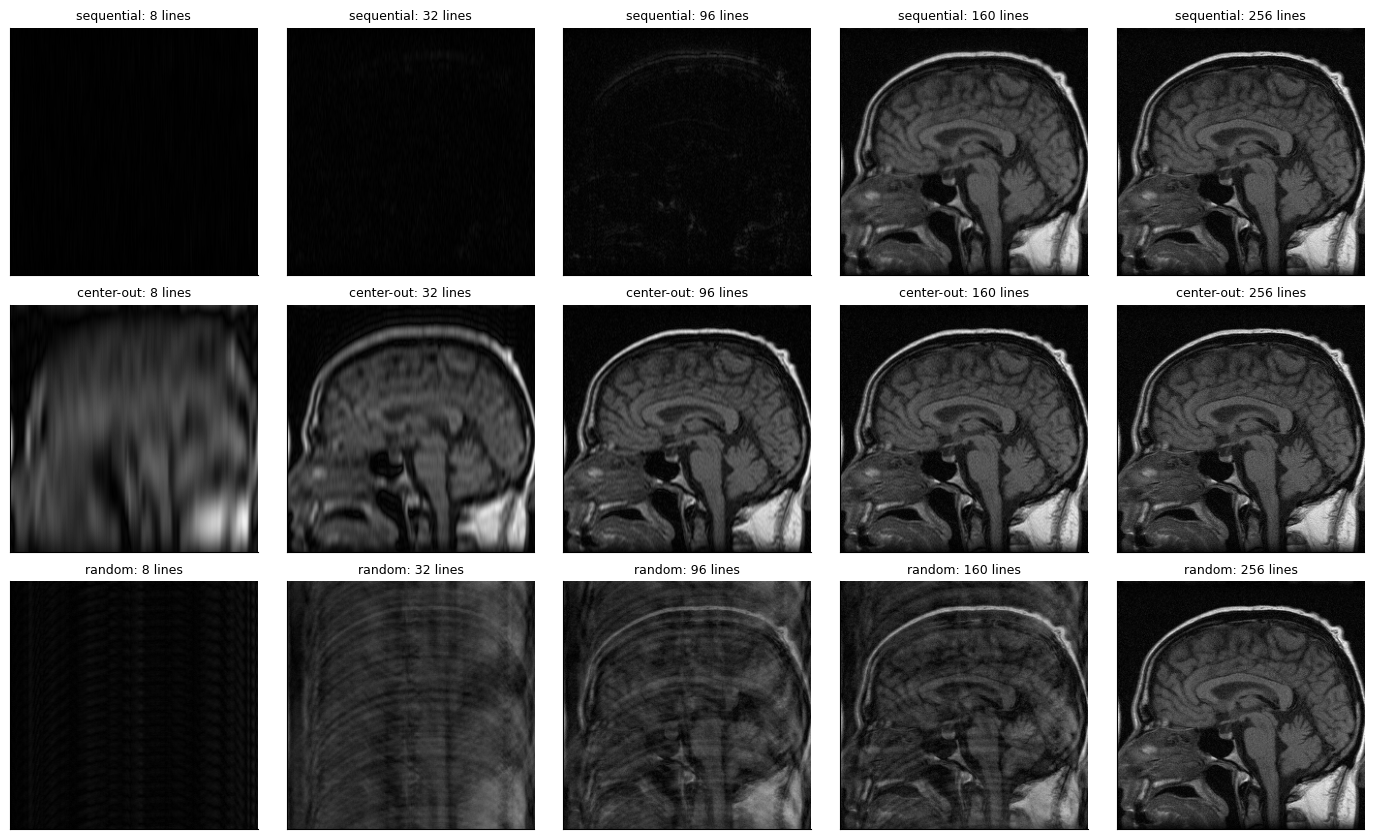

In [5]:
Ny = kspace.shape[0]
rng = np.random.default_rng(1)
ky_index = np.arange(Ny) - Ny // 2                  # k_y in units of Delta k_y
orders = {
    'sequential': np.arange(Ny),                     # top to bottom, as acquired by a linear PE order
    'center-out': np.argsort(np.abs(ky_index), kind='stable'),
    'random':     rng.permutation(Ny),
}
n_lines = [8, 32, 96, 160, 256]

fig, axs = plt.subplots(3, len(n_lines), figsize=(14, 8.5))
for r, (name, order) in enumerate(orders.items()):
    for c, n in enumerate(n_lines):
        kpart = np.zeros_like(kspace)
        kpart[order[:n], :] = kspace[order[:n], :]   # only the first n acquired lines are present
        mt.show_image(mt.ifft2c(kpart), ax=axs[r, c], vmin=0, vmax=np.abs(recon_image).max())
        axs[r, c].set_title(f'{name}: {n} lines', fontsize=9)
plt.tight_layout(); plt.show()

After 32 center-out lines (1/8 of the data) the anatomy and contrast are already visible, only blurred; random lines give the full resolution immediately but with strong ghosting/noise-like artifacts. This is the root of contrast-controlling "centric" orderings (Fast Spin Echo, MPRAGE) and of compressed sensing's random undersampling ([Accelerated Imaging Methods](H3_Accelerated_Imaging_Methods.ipynb)).

## 4. Centered FFTs: the bookkeeping that trips everybody up

`numpy.fft.fft` (like every FFT library) assumes the **zero frequency is at index 0** and the frequencies run $0,1,\dots,N/2-1,-N/2,\dots,-1$ ("wrap-around order"), and likewise that the **origin $x=0$ is at index 0**. MRI data and images, however, are stored **centered**: $k=0$ at index $N/2$ and $x=0$ at index $N/2$. The centered transforms in `mri_tools` therefore do three steps:

```python
mt.ifft2c(K) = fftshift( ifft2( ifftshift(K) ) )
```

1. `ifftshift`: move the k-space center from index $N/2$ to index 0 (what the FFT expects),
2. `ifft2`: the actual transform,
3. `fftshift`: move the image origin from index 0 back to the middle for display.

(`norm="ortho"` additionally scales by $1/\sqrt{N}$ per dimension so that the transform is **unitary**: it preserves energy and noise level — [Parseval, RM4](../refreshers/RM4_Fourier_Properties.ipynb).)

What happens if you skip a shift? For even $N$, putting centered data into a plain `ifft2` means every sample index is off by $N/2$, i.e. the k-space is shifted by half its width. By the shift theorem that multiplies the image by $e^{i2\pi (N/2) q/N}=e^{i\pi q}=(-1)^q$ — a **checkerboard sign pattern** — and the missing output shift leaves the image origin at the corner — **swapped quadrants**.

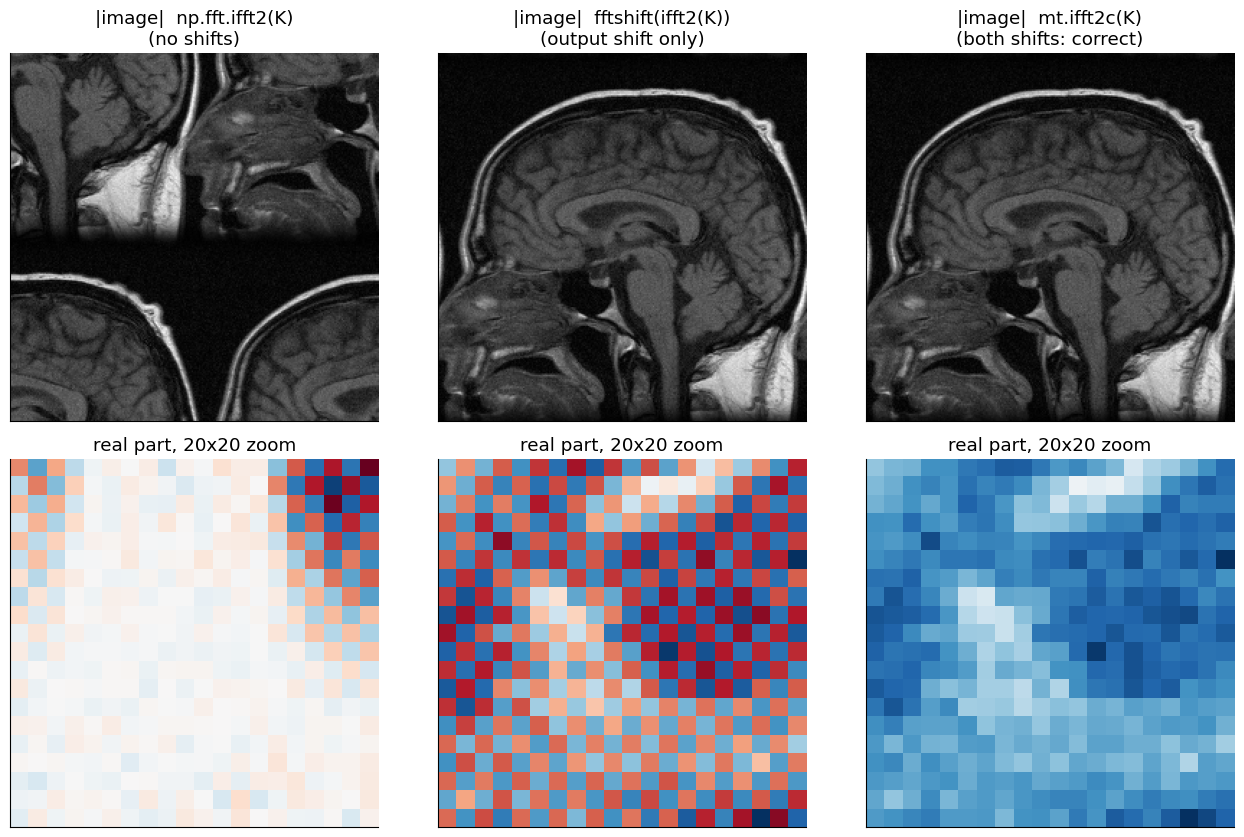

In [6]:
variants = {
    'np.fft.ifft2(K)\n(no shifts)':                 np.fft.ifft2(kspace),
    'fftshift(ifft2(K))\n(output shift only)':      np.fft.fftshift(np.fft.ifft2(kspace)),
    'mt.ifft2c(K)\n(both shifts: correct)':         mt.ifft2c(kspace),
}
fig, axs = plt.subplots(2, 3, figsize=(13, 8.5))
for c, (name, im) in enumerate(variants.items()):
    mt.show_image(np.abs(im), ax=axs[0, c], title='|image|  ' + name)
    zoom = im[118:138, 118:138].real                  # 20 x 20 pixel zoom of the real part
    v = np.abs(zoom).max()
    axs[1, c].imshow(zoom, cmap='RdBu_r', vmin=-v, vmax=v)
    axs[1, c].set_title('real part, 20x20 zoom'); axs[1, c].set_xticks([]); axs[1, c].set_yticks([]); axs[1, c].grid(False)
plt.tight_layout(); plt.show()

Left: quadrants swapped (the head is cut into four pieces at the corners). Middle: magnitude looks perfect, but the real part flips sign from pixel to pixel — harmless for a magnitude display, fatal for anything that uses the complex values (coil combination with phases, phase maps, further Fourier processing). Right: correct.

> **📐 Math note:** For **odd** $N$, `fftshift` and `ifftshift` differ by one sample, which is why both are needed in the right order. For even $N$ they are identical, but writing both documents intent. Different software packages (MATLAB's `ifft2c` in the original, BART, SigPy, `fastMRI`) use the same convention; mixing conventions between packages is a classic source of the checkerboard.

## 5. Conjugate (Hermitian) symmetry

A Fourier fact ([RM4](../refreshers/RM4_Fourier_Properties.ipynb)): if $m(\vec r)$ is **real**, then

$$ M(-\vec k) = M^*(\vec k) $$

In words: for a real object, the k-space value at $-\vec k$ is the complex conjugate of the value at $+\vec k$ — half of k-space is redundant.

where $^*$ = complex conjugate. (Proof: $M^*(\vec k)=\int m^*(\vec r)e^{+i2\pi\vec k\cdot\vec r}d\vec r = \int m(\vec r)e^{-i2\pi(-\vec k)\cdot\vec r}d\vec r = M(-\vec k)$ when $m=m^*$.)

Tempting conclusion: "measure only half of k-space and fill in the rest" (**partial Fourier**). The catch is that MRI images are *not* real (Section 3.2). Let us measure how far each k-space is from being Hermitian, using $\epsilon = \|M(\vec k)-M^*(-\vec k)\|/\|M\|$.

Shepp-Logan (real object):   epsilon = 2.72e-16
Measured brain k-space:      epsilon = 1.34


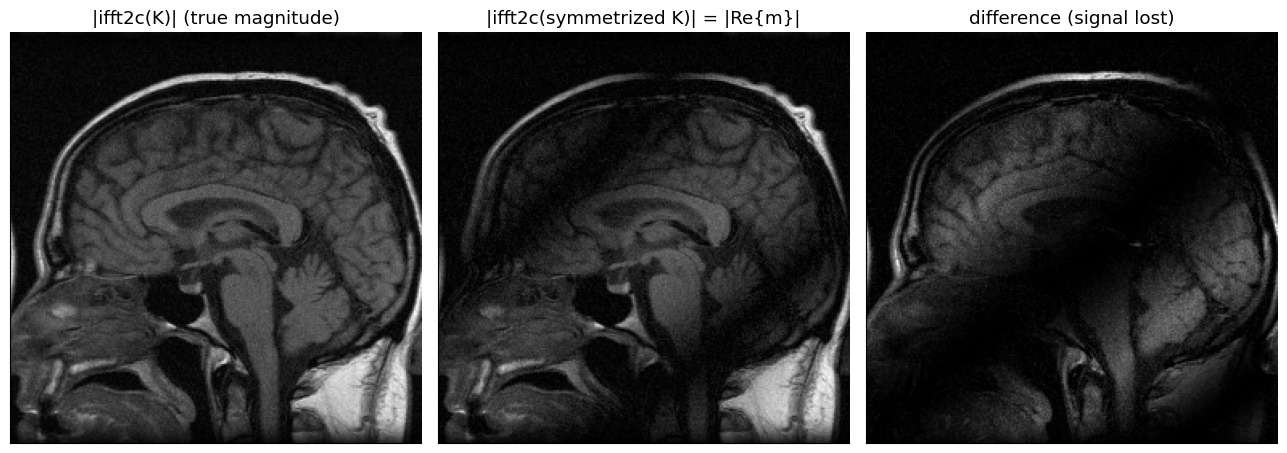

In [7]:
def mirror_k(K):
    """Return K evaluated at -k for a centered array (k index j -> N - j, i.e. flip then roll by one)."""
    return np.roll(K[::-1, ::-1], shift=(1, 1), axis=(0, 1))

def hermitian_error(K):
    return np.linalg.norm(K - np.conj(mirror_k(K))) / np.linalg.norm(K)

K_sl = mt.fft2c(mt.shepp_logan(256))                 # k-space of a REAL phantom
print(f"Shepp-Logan (real object):   epsilon = {hermitian_error(K_sl):.2e}")
print(f"Measured brain k-space:      epsilon = {hermitian_error(kspace):.2f}")

# Enforcing symmetry keeps only the real part of the image: (K + conj(K(-k)))/2  <->  Re{m}
K_sym = 0.5 * (kspace + np.conj(mirror_k(kspace)))
fig, axs = plt.subplots(1, 3, figsize=(13, 4.5))
mt.show_image(recon_image, ax=axs[0], title='|ifft2c(K)| (true magnitude)')
mt.show_image(mt.ifft2c(K_sym), ax=axs[1], title='|ifft2c(symmetrized K)| = |Re{m}|')
mt.show_image(np.abs(recon_image) - np.abs(mt.ifft2c(K_sym)), ax=axs[2], title='difference (signal lost)')
plt.tight_layout(); plt.show()

The phantom is Hermitian to machine precision, the measured data are far from it; naively forcing symmetry produces dark bands wherever the image phase is near $\pm\pi/2$. Partial-Fourier methods therefore first estimate the smooth image phase from a fully sampled central k-space strip and then exploit symmetry only after removing that phase ("homodyne" or POCS reconstruction — see [Accelerated Imaging Methods](H3_Accelerated_Imaging_Methods.ipynb)).

## 6. Linear system formulation

Alternatively, reconstruction can be formulated as a **linear system** using an encoding matrix $\mathbf{F}$. Stack all pixel values into a vector $\mathbf x$ (length $N_{pix}$) and all measured samples into $\mathbf y$ (length $N_{samp}$). Each measured sample is a weighted sum of all pixels (the discrete signal equation), so

$$ \mathbf{F}_{pq} = \exp(-i 2 \pi \vec{k}_p \cdot \vec{r}_q), \qquad \mathbf{y} = \mathbf{F}\mathbf{x} + \mathbf{n} $$

In words: row $p$ of $\mathbf F$ is the stripe pattern that the gradients imposed when sample $p$ was recorded; the measurement is the inner product of that pattern with the image, plus noise.

where $\vec k_p$ = k-space location of sample $p$, $\vec r_q$ = position of pixel $q$, $\mathbf n$ = complex Gaussian noise. (The original wrote the entries as $f_{i,j}$ — renamed here because $i$ is also $\sqrt{-1}$ in the same formula.)

For fully sampled Cartesian 2D FT imaging, $\mathbf F$ is square and its columns are orthogonal: $\mathbf F^H\mathbf F = N_{pix}\,\mathbf I$. Hence the inverse is just the conjugate transpose, **scaled**:

$$ \hat{\mathbf{x}} = \mathbf F^{-1}\mathbf y = \frac{1}{N_{pix}}\mathbf{F}^{H} \mathbf{y} $$

In words: to undo the encoding, correlate the data with each pixel's pattern (that is what $\mathbf F^H$ does) and divide by the number of pixels. (The original omitted the factor $1/N_{pix}$; with the unitary scaling $\mathbf F/\sqrt{N_{pix}}$ used by `norm="ortho"` the inverse is exactly the conjugate transpose.)

where $\hat{\mathbf x}$ = reconstructed image vector, $\mathbf I$ = identity matrix, $(\cdot)^H$ = conjugate transpose. Let us build $\mathbf F$ explicitly for a small $16\times16$ image and compare with the FFT.

2D encoding matrix shape: (256, 256)
F^H F = N_pix I ? True
matrix model == centered FFT ? True
F^H y / N_pix == ifft2c ? True


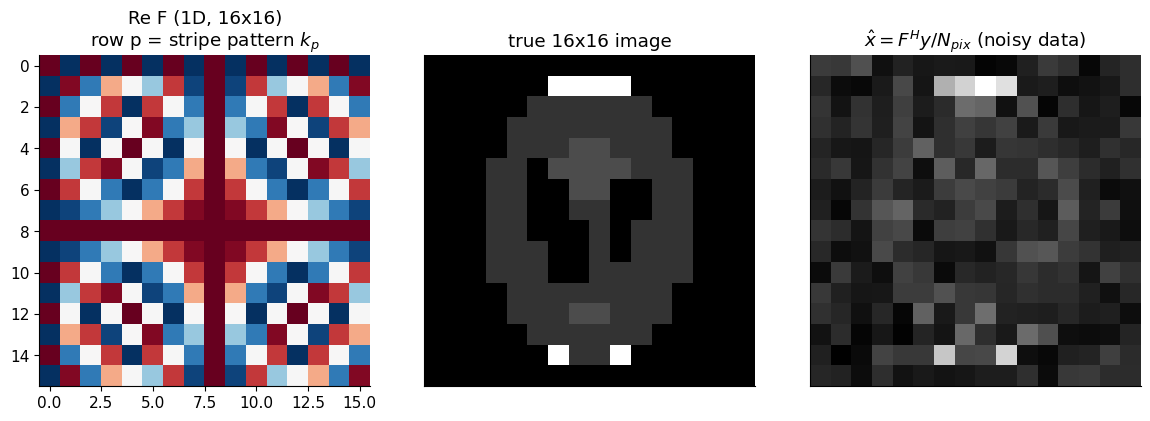

In [8]:
N = 16
q = np.arange(N) - N // 2                 # pixel positions in units of delta  (r_q)
p = np.arange(N) - N // 2                 # k-space positions in units of Delta k (k_p), Delta k * delta = 1/N
F1 = np.exp(-1j * 2 * np.pi * np.outer(p, q) / N)     # 1D encoding matrix, F1[p, q] = exp(-i 2 pi k_p x_q)
F2 = np.kron(F1, F1)                                   # 2D: rows = (k_y, k_x) pairs, columns = (y, x) pixels
print("2D encoding matrix shape:", F2.shape)
print("F^H F = N_pix I ?", np.allclose(F2.conj().T @ F2, N * N * np.eye(N * N)))

x_true = mt.shepp_logan(N).ravel()                      # image as a vector (row-major: y slow, x fast)
y = F2 @ x_true                                         # "measurement" (noiseless)
print("matrix model == centered FFT ?", np.allclose(y.reshape(N, N), mt.fft2c(mt.shepp_logan(N), norm=None)))

y_noisy = mt.add_complex_noise(y, sigma=2.0)            # y = F x + n
x_hat = (F2.conj().T @ y_noisy) / (N * N)               # x_hat = F^H y / N_pix
x_fft = mt.ifft2c(y_noisy.reshape(N, N), norm=None)     # same thing with the FFT (unnormalized inverse includes 1/N_pix)
print("F^H y / N_pix == ifft2c ?", np.allclose(x_hat.reshape(N, N), x_fft))

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
axs[0].imshow(F1.real, cmap='RdBu_r'); axs[0].set_title('Re F (1D, 16x16)\nrow p = stripe pattern $k_p$'); axs[0].grid(False)
mt.show_image(x_true.reshape(N, N), ax=axs[1], title='true 16x16 image')
mt.show_image(x_hat.reshape(N, N), ax=axs[2], title=r'$\hat{x}=F^H y/N_{pix}$ (noisy data)')
plt.tight_layout(); plt.show()

The explicit matrix and the FFT give identical results; the FFT is just a fast way of multiplying by $\mathbf F^H$. Each row of $\mathbf F$ is a sampled complex exponential, the lowest frequencies in the middle rows.

| Operation for an $N\times N$ image | Explicit matrix $\mathbf F^H\mathbf y$ | FFT |
|---|---|---|
| multiplications | $N^4$ (65 536 for $N=16$; $4.3\times10^9$ for $N=256$) | $\sim 2N^2\log_2N$ ($\approx10^6$ for $N=256$) |
| memory for $\mathbf F$ | $N^4$ complex numbers (69 GB at $N=256$!) | none |

So why bother with the matrix view? Because as soon as the data are **not** a complete Cartesian grid — undersampled lines, several coils with different sensitivities $C_n$, non-Cartesian trajectories, field-inhomogeneity terms — $\mathbf F$ is no longer a plain DFT, $\mathbf F^H$ is no longer the inverse, and one solves $\min_{\mathbf x}\|\mathbf y-\mathbf E\mathbf x\|^2+\text{regularization}$ iteratively (with an "encoding operator" $\mathbf E$ that is applied using FFTs, never stored). That is SENSE, compressed sensing, and model-based reconstruction: see [Accelerated Imaging Methods](H3_Accelerated_Imaging_Methods.ipynb) and [Advanced Image Reconstruction](J5_Advanced_Image_Reconstruction.ipynb).

> **🧭 Intuition:** Because $\mathbf F/\sqrt{N_{pix}}$ is unitary (a rotation in $N_{pix}$-dimensional complex space), white noise in k-space stays white noise of the same per-sample level in the image. Reconstruction neither creates nor removes noise — it only redistributes it.

## 7. A second real dataset: oversampled knee, coronal fat-saturated

`../data/coronal_fatsat_2D_knee.mat` (variable `kdata`) is a $332\times640$ k-space: 332 phase-encode lines and 640 readout samples. 640 is twice the displayed matrix: the scanner used the common **2× readout oversampling** — it sampled the readout twice as fast (dwell time $\Delta t/2$), which doubles $FOV_x$ ([FOV and Resolution](G1_FOV_and_Resolution.ipynb)) at **no cost in scan time**. The reconstruction must then discard the outer half of the image in the readout direction:

1. inverse FFT along the readout axis (axis 1) → hybrid space ($x$, $k_y$),
2. keep the central 320 of the 640 $x$ positions,
3. inverse FFT along the phase-encode axis (axis 0).

Cropping after the 1D FFT (rather than after the 2D FFT) halves the work of step 3 — real reconstruction pipelines do exactly this.

knee k-space: 332 phase encodes x 640 readout samples, center at (166, 320)


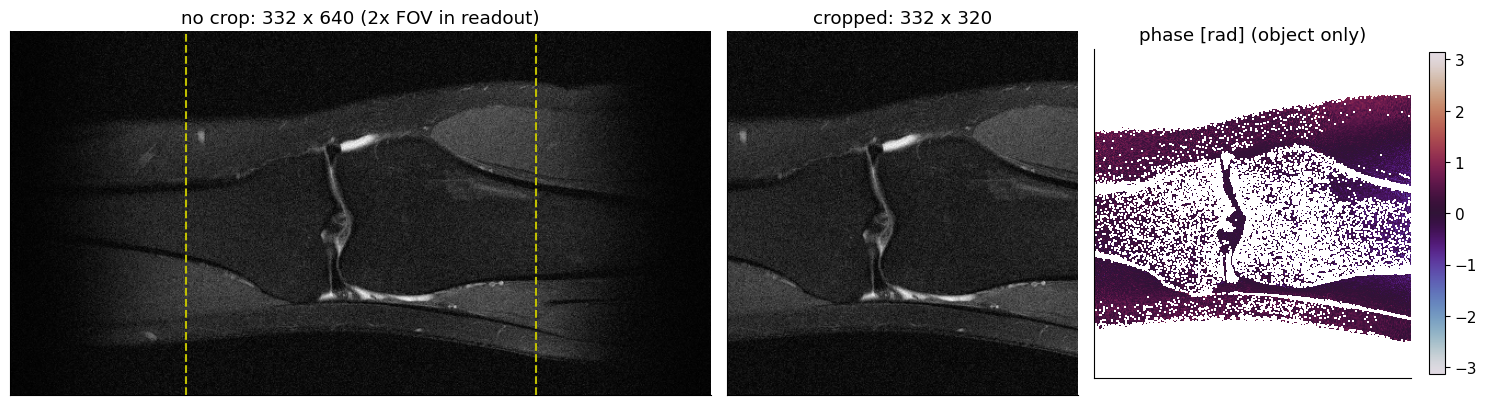

In [9]:
kknee = loadmat('../data/coronal_fatsat_2D_knee.mat')['kdata']
N_pe, N_ro = kknee.shape
print(f"knee k-space: {N_pe} phase encodes x {N_ro} readout samples, center at",
      np.unravel_index(np.argmax(np.abs(kknee)), kknee.shape))

OS = 2                                              # readout oversampling factor
hybrid = mt.ifftc(kknee, axis=1)                    # step 1: readout direction -> x
n_keep = N_ro // OS
start = (N_ro - n_keep) // 2
hybrid_crop = hybrid[:, start:start + n_keep]       # step 2: keep central FOV_x / OS
knee = mt.ifftc(hybrid_crop, axis=0)                # step 3: phase-encode direction -> y

full = mt.ifft2c(kknee)                             # for comparison: no cropping
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={'width_ratios': [2, 1, 1]})
mt.show_image(full, ax=axs[0], title=f'no crop: {N_pe} x {N_ro} (2x FOV in readout)')
axs[0].axvline(start, color='y', ls='--'); axs[0].axvline(start + n_keep, color='y', ls='--')
mt.show_image(knee, ax=axs[1], title=f'cropped: {knee.shape[0]} x {knee.shape[1]}')
im = axs[2].imshow(np.where(np.abs(knee) > 0.1 * np.abs(knee).max(), np.angle(knee), np.nan),
                   cmap='twilight', vmin=-np.pi, vmax=np.pi)
axs[2].set_title('phase [rad] (object only)'); axs[2].set_xticks([]); axs[2].set_yticks([]); axs[2].grid(False)
plt.colorbar(im, ax=axs[2], fraction=0.046)
plt.tight_layout(); plt.show()

The uncropped image (left, readout horizontal) shows the full doubled FOV — the thigh and calf extend all the way to the edges; the yellow lines mark the part kept. The cropped $332\times320$ image is what the scanner would display; fat is dark because of the fat-saturation preparation, fluid is bright. Why oversample at all if half is thrown away? Because the receiver's anti-aliasing filter is not infinitely sharp; oversampling pushes its roll-off and any wrap-around outside the displayed FOV ([FOV and Resolution](G1_FOV_and_Resolution.ipynb)).

## 8. Multiple receive coils: root-sum-of-squares combination

Modern scanners receive with **arrays** of 8–64 small coils (channels), each recording its own k-space simultaneously ([RF System and Receive Chain](B5_RF_System_and_Receive_Chain.ipynb)). Coil $n$ sees the object weighted by its complex sensitivity:

$$ m_n(\vec r) = C_n(\vec r)\, m(\vec r), \qquad n = 1,\dots,N_c $$

In words: each coil delivers its own image of the same object, bright near the coil and dark far away, with its own smoothly varying phase.

where $C_n(\vec r)$ = complex receive sensitivity of coil $n$ (by reciprocity, proportional to the field the coil would produce at $\vec r$ per unit current — [RP2](../refreshers/RP2_Induction_and_RF.ipynb)), $N_c$ = number of coils. Each coil's k-space is reconstructed separately with an inverse FFT, then the coil images are **combined**. Without knowing the $C_n$, the standard choice is the **root sum of squares (SoS)**:

$$ m_{SoS}(\vec r) = \sqrt{\sum_{n=1}^{N_c} |m_n(\vec r)|^2} = |m(\vec r)|\sqrt{\sum_{n} |C_n(\vec r)|^2} $$

In words: add up the *energies* of all coil images pixel by pixel and take the square root. Phases cancel out (no destructive interference), and every coil contributes most where it is most sensitive.

where $m_{SoS}$ = combined magnitude image. The last expression shows its two properties: (1) the result is a magnitude image, (2) it is weighted by the smooth "sum-of-sensitivities" profile $\sqrt{\sum|C_n|^2}$ (brighter near the coils), which scanners partly remove with an intensity-normalization filter.

No multi-coil raw data are provided, so we **simulate** four loop coils around the sagittal brain image: the sensitivity of each loop is taken as $B_x - iB_y$ of its Biot–Savart field in the image plane (`mt.loop_coil_field`), a standard textbook proxy.

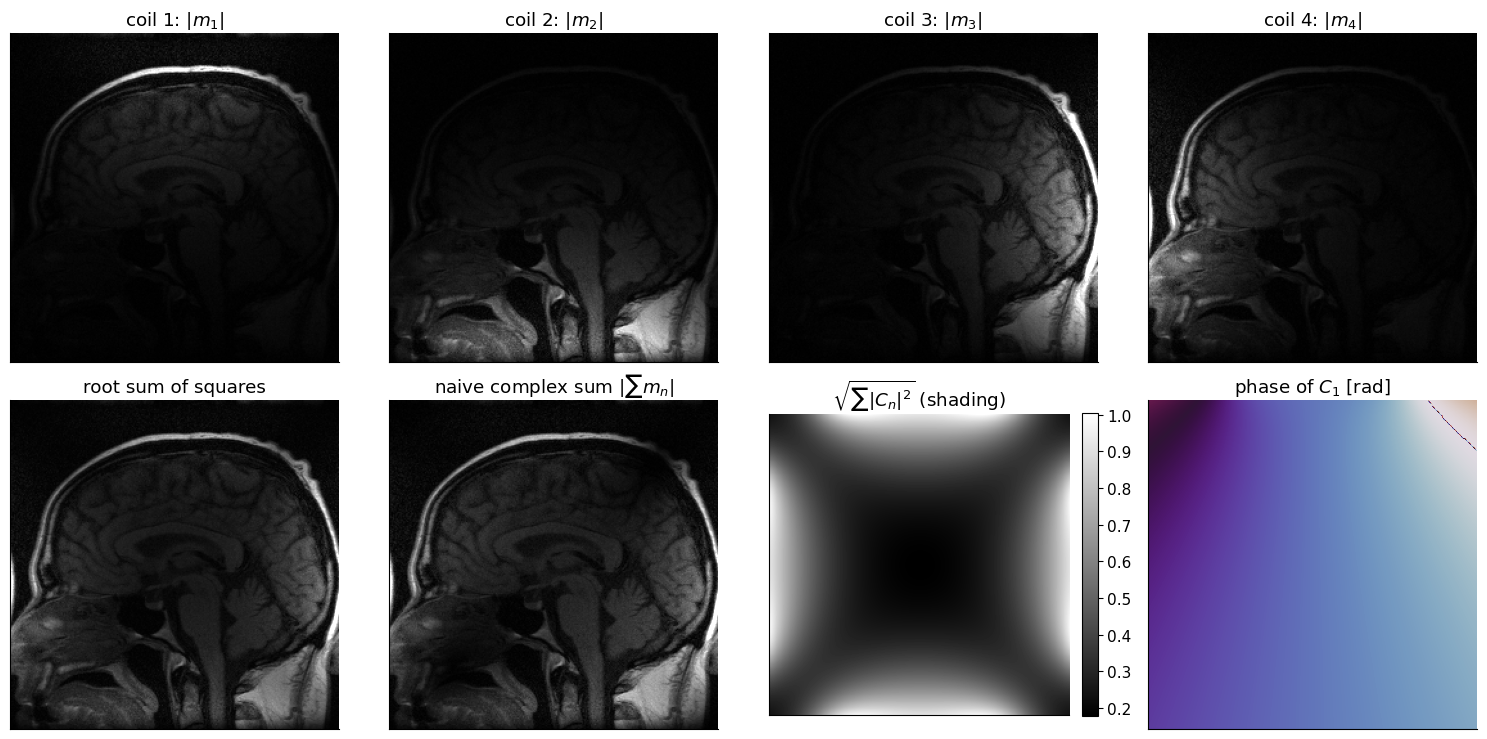

In [10]:
N = 256
FOV = 0.24                                           # assumed field of view [m] (240 mm)
xpos = (np.arange(N) - N // 2) / N * FOV             # pixel positions [m]
X, Y = np.meshgrid(xpos, -xpos)                      # image rows run downward -> y = -row
pts = np.stack([X, Y, np.zeros_like(X)], axis=-1)    # image plane = z = 0

coils = [((0, 0.15, 0), 'y'), ((0, -0.15, 0), 'y'), ((0.15, 0, 0), 'x'), ((-0.15, 0, 0), 'x')]   # (center [m], axis)
C = []
for center, axis in coils:
    B = mt.loop_coil_field(pts, radius=0.07, current=1.0, center=center, normal=axis, n_segments=60)
    C.append(B[..., 0] - 1j * B[..., 1])             # receive-sensitivity proxy (complex)
C = np.array(C) / np.max(np.abs(C))                  # (Nc, N, N), normalized

m_true = recon_image / np.abs(recon_image).max()     # treat the single-coil image as the "object"
k_coils = mt.fft2c(C * m_true)                       # what each coil would measure (Nc k-spaces)
k_coils = mt.add_complex_noise(k_coils, sigma=2e-3)  # independent receiver noise per coil

coil_imgs = mt.ifft2c(k_coils)                       # reconstruct each coil separately
sos = np.sqrt(np.sum(np.abs(coil_imgs) ** 2, axis=0))
single_sum = np.abs(np.sum(coil_imgs, axis=0))       # naive complex sum, for comparison

fig, axs = plt.subplots(2, 4, figsize=(15, 7.5))
for n in range(4):
    mt.show_image(coil_imgs[n], ax=axs[0, n], vmin=0, vmax=np.percentile(np.abs(coil_imgs), 99.8), title=f'coil {n+1}: $|m_{n+1}|$')
mt.show_image(sos, ax=axs[1, 0], vmin=0, vmax=np.percentile(sos, 99.8), title='root sum of squares')
mt.show_image(single_sum, ax=axs[1, 1], vmin=0, vmax=np.percentile(sos, 99.8), title='naive complex sum $|\\sum m_n|$')
mt.show_image(np.sqrt(np.sum(np.abs(C) ** 2, 0)), ax=axs[1, 2], colorbar=True, title=r'$\sqrt{\sum|C_n|^2}$ (shading)')
im = axs[1, 3].imshow(np.angle(C[0]), cmap='twilight', vmin=-np.pi, vmax=np.pi); axs[1, 3].set_title('phase of $C_1$ [rad]')
axs[1, 3].set_xticks([]); axs[1, 3].set_yticks([]); axs[1, 3].grid(False)
plt.tight_layout(); plt.show()

Each coil sees only "its" part of the head well. The SoS image covers the whole head, with brighter periphery (the shading map) — real head arrays show the same center-darker look before intensity correction. The naive complex sum suffers where coil phases differ: signals partially cancel.

> **📐 Math note (noise in SoS):** In the noise-only background, SoS of $N_c$ channels is the magnitude of an $N_c$-dimensional complex Gaussian: its values follow a (non-central) **chi distribution** with $2N_c$ degrees of freedom, so the background is not zero on average — a *bias* of about $\sigma_n\sqrt{2N_c}$ for large $N_c$. In high-SNR tissue, SoS is close to the SNR-optimal combination $\hat m=\sum_n C_n^* m_n/\sum_n|C_n|^2$ (Roemer et al. 1990), which needs the sensitivities $C_n$ (and the noise covariance between channels). Measuring/estimating $C_n$ is also the basis of parallel imaging (SENSE, GRAPPA): [Accelerated Imaging Methods](H3_Accelerated_Imaging_Methods.ipynb), [Advanced SNR](J4_Advanced_SNR.ipynb), [Advanced Image Reconstruction](J5_Advanced_Image_Reconstruction.ipynb).

Let us check the bias with pure noise (no object at all), reconstructed and combined exactly like the coil data:

In [11]:
from scipy.special import gamma as Gamma
sigma = 2e-3                                          # per real/imag part; ortho FFT keeps it the same in the image
Nc = len(coils)
noise_imgs = mt.ifft2c(mt.add_complex_noise(np.zeros((Nc, N, N)), sigma, rng=np.random.default_rng(5)))
sos_noise = np.sqrt(np.sum(np.abs(noise_imgs) ** 2, axis=0))
chi_mean = sigma * np.sqrt(2) * Gamma(Nc + 0.5) / Gamma(Nc)     # exact mean of a chi variable with 2*Nc degrees of freedom
print(f"mean of SoS of pure noise = {sos_noise.mean():.5f}")
print(f"chi_(2Nc) theory          = {chi_mean:.5f}   (large-Nc approximation sigma*sqrt(2Nc) = {sigma*np.sqrt(2*Nc):.5f})")
print(f"single-channel magnitude mean = {np.abs(noise_imgs[0]).mean():.5f}  (Rayleigh: sigma*sqrt(pi/2) = {sigma*np.sqrt(np.pi/2):.5f})")

mean of SoS of pure noise = 0.00548
chi_(2Nc) theory          = 0.00548   (large-Nc approximation sigma*sqrt(2Nc) = 0.00566)
single-channel magnitude mean = 0.00250  (Rayleigh: sigma*sqrt(pi/2) = 0.00251)


The noise-only SoS is indeed biased upward to $\approx\sigma_n\sqrt{2N_c}$ (larger than a single channel's Rayleigh mean) — never subtract "background" from SoS images assuming zero-mean noise, and measure SNR in such images with care ([Signal to Noise Ratio](G2_Signal_to_Noise_Ratio.ipynb)). (In the brain demo the background is even higher because the "object" image we started from already contained the original scan's noise.)

## 9. 3D phase encoding: a spectroscopic-imaging phantom

`../data/prose_phantom_data.mat` (variable `raw_data`, shape $1024\times8\times8\times8$) is a **chemical-shift imaging** (CSI, or MR spectroscopic imaging, MRSI) dataset of a phantom. Here **all three spatial dimensions are phase-encoded** ($8\times8\times8=512$ repetitions) and *no* readout gradient is applied: the 1024 samples of each readout record the free induction decay (FID) as a function of time, whose Fourier transform is a **spectrum** of chemical shifts ([In Vivo Spin Physics](A3_In_Vivo_Spin_Physics.ipynb)). Reconstruction is a 3D inverse FFT over the phase-encode axes plus a 1D FFT over time:

* In the file, the FID starts at sample 512 (the time axis is stored circularly shifted); we undo that with `ifftshift` along axis 0. A circular shift in time only changes the *phase* of the spectrum, not its magnitude ([shift theorem, RM4](../refreshers/RM4_Fourier_Properties.ipynb)).
* The dwell time (spectral bandwidth) is not stored in the file, so the frequency axis is given in **bins**.

CSI raw data: (1024, 8, 8, 8) | k-space center (largest |sample|): (512, 4, 3, 4)


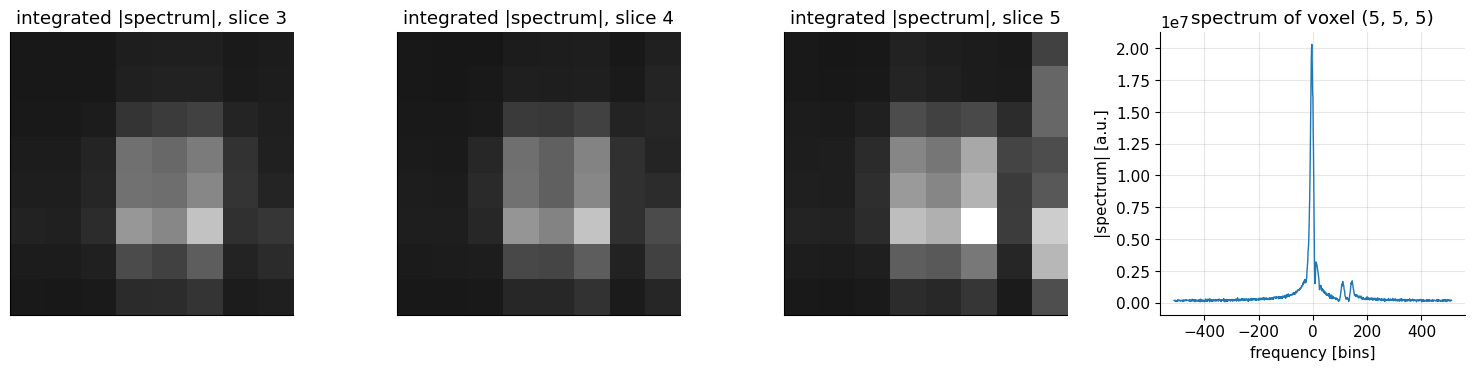

In [12]:
raw = loadmat('../data/prose_phantom_data.mat')['raw_data']           # (time, k1, k2, k3)
print("CSI raw data:", raw.shape, "| k-space center (largest |sample|):", np.unravel_index(np.argmax(np.abs(raw)), raw.shape))
fid = np.fft.ifftshift(raw, axes=0)                                    # FID now starts at t-index 0
img3d = mt.ifftc(mt.ifftc(mt.ifftc(fid, axis=1), axis=2), axis=3)      # 3D spatial reconstruction (8x8x8 voxels)
spec = mt.fftc(img3d, axis=0)                                          # time -> frequency, per voxel
f_bins = np.arange(raw.shape[0]) - raw.shape[0] // 2

total = np.abs(spec).sum(axis=0)                                       # "image" = integrated |spectrum|
best = np.unravel_index(np.argmax(total), total.shape)

fig = plt.figure(figsize=(15, 4))
for s in range(3, 6):
    ax = fig.add_subplot(1, 4, s - 2)
    mt.show_image(total[:, :, s], ax=ax, vmin=0, vmax=total.max(), title=f'integrated |spectrum|, slice {s}')
ax = fig.add_subplot(1, 4, 4)
ax.plot(f_bins, np.abs(spec[(slice(None),) + best]), lw=1)
ax.set_xlabel('frequency [bins]'); ax.set_ylabel('|spectrum| [a.u.]'); ax.set_title(f'spectrum of voxel {best}')
plt.tight_layout(); plt.show()

With only 8 phase encodes per direction the "image" is very coarse (each voxel is 1/8 of the FOV), but every voxel carries a full spectrum: one dominant peak plus smaller peaks of other molecules. This is the price of phase encoding everything: $N_{PE}=512$ repetitions for just $8^3$ voxels — which is why imaging uses frequency encoding for one direction whenever possible ([Spatial Encoding](F1_Spatial_Encoding.ipynb)).

## 10. Non-Cartesian data: the idea of gridding

For radial, spiral, or other non-Cartesian trajectories ([K-space](F2_K-space.ipynb)), the samples $\vec k_p$ do not lie on a grid, so an FFT cannot be applied directly. The exact adjoint $\mathbf F^H\mathbf y=\sum_p y_p e^{+i2\pi\vec k_p\cdot\vec r}$ can be computed directly but (i) it is slow ($N_{samp}\times N_{pix}$ operations) and (ii) it is **not** the inverse, because samples are denser in some regions (radial: crowded near the center). Two ingredients fix this:

1. **Density compensation**: weight each sample by $w_p\approx$ the k-space area it represents (radial: $w_p\propto|\vec k_p|$), so the sum approximates the inverse Fourier *integral*.
2. **Gridding**: convolve the weighted samples onto a Cartesian grid with a small kernel (usually Kaiser–Bessel on a 1.25–2× oversampled grid), FFT, then divide by the kernel's Fourier transform ("deapodization"). Libraries: NUFFT (e.g. FINUFFT, SigPy, BART).

The demo below uses a $64\times64$ phantom, 101 radial spokes, the exact (slow) adjoint with and without density compensation, and the crudest gridding (nearest-neighbor) to show the idea.

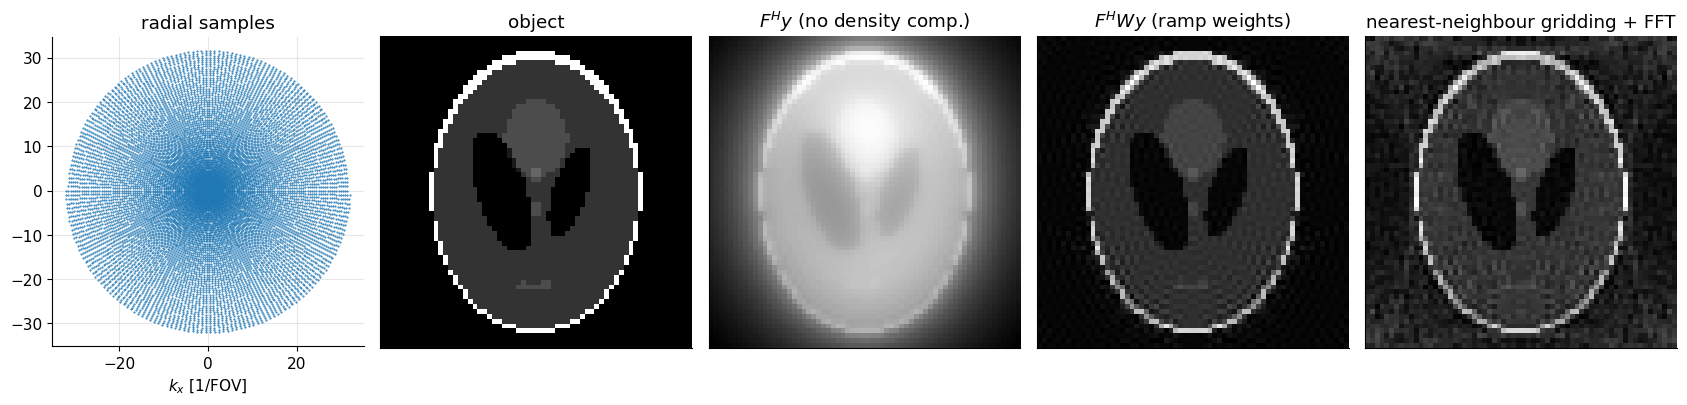

In [13]:
N = 64
obj = mt.shepp_logan(N)
xg = (np.arange(N) - N // 2) / N                        # pixel positions in units of FOV
Xg, Yg = np.meshgrid(xg, xg)
n_spokes, n_read = 101, 2 * N
kr = (np.arange(n_read) - n_read // 2) / 2               # radial k from -N/2 to N/2 [cycles/FOV]
ang = np.pi * np.arange(n_spokes) / n_spokes
KX = np.outer(np.cos(ang), kr).ravel(); KY = np.outer(np.sin(ang), kr).ravel()

def nudft(img, kx, ky, adjoint=False, chunk=2000):
    """Exact non-uniform DFT (forward: image -> samples; adjoint: samples -> image)."""
    out = np.zeros(Xg.size, complex) if adjoint else np.zeros(kx.size, complex)
    for s in range(0, kx.size, chunk):
        E = np.exp(-1j * 2 * np.pi * (np.outer(kx[s:s+chunk], Xg.ravel()) + np.outer(ky[s:s+chunk], Yg.ravel())))
        if adjoint:
            out += E.conj().T @ img[s:s+chunk]
        else:
            out[s:s+chunk] = E @ img.ravel()
    return out.reshape(N, N) if adjoint else out

y_rad = nudft(obj, KX, KY)                               # simulated radial measurement
w = np.abs(np.hypot(KX, KY)); w[w == 0] = 0.25           # ramp density compensation (small weight at the center)
adj_plain = nudft(y_rad, KX, KY, adjoint=True)
adj_dcf = nudft(w * y_rad, KX, KY, adjoint=True)

# nearest-neighbour gridding onto the Cartesian grid, then a plain inverse FFT
grid = np.zeros((N, N), complex)
ix = np.clip(np.round(KX).astype(int) + N // 2, 0, N - 1); iy = np.clip(np.round(KY).astype(int) + N // 2, 0, N - 1)
np.add.at(grid, (iy, ix), w * y_rad)
nn_img = mt.ifft2c(grid)

fig, axs = plt.subplots(1, 5, figsize=(17, 3.8))
axs[0].plot(KX, KY, '.', ms=1); axs[0].set_aspect('equal'); axs[0].set_title('radial samples'); axs[0].set_xlabel('$k_x$ [1/FOV]')
mt.show_image(obj, ax=axs[1], title='object')
mt.show_image(adj_plain, ax=axs[2], title='$F^H y$ (no density comp.)')
mt.show_image(adj_dcf, ax=axs[3], title='$F^H W y$ (ramp weights)')
mt.show_image(nn_img, ax=axs[4], title='nearest-neighbour gridding + FFT')
plt.tight_layout(); plt.show()

Without density compensation the oversampled center dominates and the image is heavily blurred; with ramp weights the exact adjoint is a good reconstruction (faint streaks remain from the finite number of spokes). Nearest-neighbor gridding is fast but adds artifacts from rounding k-space positions — proper kernels and deapodization remove them ([Advanced Image Reconstruction](J5_Advanced_Image_Reconstruction.ipynb)).

> **🔧 Engineering reality:** Non-Cartesian reconstruction needs the *actual* k-space trajectory. Gradient delays of a few µs and eddy currents ([Gradient System Engineering](B4_Gradient_System_Engineering.ipynb)) shift the real trajectory away from the nominal one, causing blurring and streaks; vendors calibrate delays or measure trajectories. Cartesian imaging is much more forgiving because errors along a line are the same for every line.

## Key takeaways

* MRI raw data are samples of the object's Fourier transform $M(\vec k)$; reconstruction sorts samples by their $\vec k$ and applies an inverse Fourier transform — for Cartesian data a 2D/3D **inverse FFT**.
* Data and images are stored **centered**; use `ifftshift → ifft → fftshift` (`mt.ifft2c`). Forgetting shifts gives swapped quadrants and/or a $(-1)^{x+y}$ checkerboard phase.
* Images are **complex**: magnitude is displayed, phase carries coil, field and flow information. Real objects would have Hermitian k-space, but MRI phase breaks this — partial Fourier needs phase correction.
* Reconstruction is the linear inverse problem $\mathbf y=\mathbf F\mathbf x+\mathbf n$; for full Cartesian sampling $\hat{\mathbf x}=\mathbf F^H\mathbf y/N_{pix}$, which the FFT evaluates fast. All advanced methods generalize this equation.
* Readout oversampling (e.g. 640 samples for a 320 matrix) is removed by cropping after the readout FFT.
* Multi-coil data are reconstructed per coil and combined, most simply by **root sum of squares** (magnitude, sensitivity-shaded, biased background).
* Non-Cartesian data need density compensation plus gridding (NUFFT) before an FFT.

## Check your understanding

1. A k-space of size $256\times256$ is stored centered. You reconstruct with `np.abs(np.fft.fftshift(np.fft.ifft2(K)))` and the magnitude image looks fine. Is your code correct?

<details><summary>Answer</summary>

Only for magnitude display. The missing `ifftshift` on the input multiplies the complex image by a $(-1)^{x+y}$ checkerboard (shift theorem with a half-width k-space shift). Magnitude is unaffected, but phase maps, complex coil combination, or any further Fourier processing would be wrong. Use `mt.ifft2c`.

</details>

2. Why can't you simply measure half of k-space and use $M(-\vec k)=M^*(\vec k)$ to fill in the rest?

<details><summary>Answer</summary>

That symmetry holds only for a real image. Real MRI images have a spatially varying phase (coil sensitivity, $B_0$ inhomogeneity, echo timing), so $M(-\vec k)\neq M^*(\vec k)$. Imposing the symmetry yields $\mathrm{Re}\{m\}$, losing signal where the phase is near $\pm\pi/2$. Partial-Fourier methods first estimate the phase from a fully sampled central strip and slightly more than half of k-space is acquired.

</details>

3. In the linear model $\mathbf y=\mathbf F\mathbf x$ for a fully sampled $128\times128$ Cartesian scan, what are the dimensions of $\mathbf F$, and why is $\mathbf F^H\mathbf y/N_{pix}$ the exact inverse?

<details><summary>Answer</summary>

$\mathbf F$ is $16384\times16384$ (one row per k-space sample, one column per pixel). Its columns are orthogonal with squared norm $N_{pix}=16384$, i.e. $\mathbf F^H\mathbf F=N_{pix}\mathbf I$, so $\mathbf F^{-1}=\mathbf F^H/N_{pix}$. The FFT applies this without storing the matrix.

</details>

4. A knee scan has a 320-pixel matrix in the readout direction but the raw data have 640 samples per readout. What happened, did it cost scan time, and how do you reconstruct?

<details><summary>Answer</summary>

2× readout oversampling: samples were taken at half the dwell time, doubling $FOV_x$ at the same $k_{x,max}$ (same resolution). Scan time is unchanged, because it is set by the number of TRs, not by the number of samples per readout. Reconstruct with an inverse FFT along the readout, keep the central 320 positions, then FFT along the phase-encode direction.

</details>

5. Why does the root-sum-of-squares image of a 32-channel coil have a non-zero background, and why is it brighter near the skull than in the center of the brain?

<details><summary>Answer</summary>

In noise-only regions, SoS is the length of a 32-dimensional complex Gaussian vector, which is always positive (chi-distributed, mean ≈ $\sigma_n\sqrt{64}$). The intensity is $|m|\sqrt{\sum_n|C_n|^2}$, and the coil sensitivities $|C_n|$ are largest close to the coil elements, i.e. at the periphery.

</details>

6. For a radial acquisition, why does the plain adjoint $\mathbf F^H\mathbf y$ give a blurred image?

<details><summary>Answer</summary>

Radial spokes all pass through the k-space center, so low spatial frequencies are sampled much more densely than high ones. The plain sum over-weights them, which acts like a low-pass filter (a $1/|k|$ weighting). Density compensation $w_p\propto|\vec k_p|$ restores the correct weighting.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Image Reconstruction". Changes: added sampling/DFT justification, centered-FFT pitfalls demo, magnitude/phase discussion, Hermitian-symmetry test, explicit DFT-matrix verification (and corrected $\hat x=\mathbf F^H\mathbf y$ to include the $1/N_{pix}$ factor; matrix indices renamed to avoid clashing with $i=\sqrt{-1}$), line-by-line snapshots (port of `animate_image_formation.m`), oversampled knee and 3D CSI reconstructions, simulated multi-coil root-sum-of-squares, and a non-Cartesian gridding demo.*